<a href="https://colab.research.google.com/github/Gonzalo-Chable/practica2-FundamentosIA/blob/main/Proyecto_evacuacuion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Documentación de diseño y modelado del problema
1.1 Representación del terreno

El terreno se modela como una matriz 2D (numpy.ndarray de enteros), donde cada celda (fila, columna) representa una porción del mapa y contiene un valor de riesgo/costo:
Valor 	Significado 	Transitable 	Costo de entrar a la celda
0 	Zona bloqueada / inundación crítica (muro) 	❌ No 	— (infranqueable)
1 	Zona seca / segura 	✅ Sí 	1 (costo base)
3 	Inundación leve / riesgo bajo 	✅ Sí 	3
5 	Inundación moderada / riesgo medio 	✅ Sí 	5
10 	Inundación severa / riesgo alto 	✅ Sí 	10

Por convención, tanto 0 como -1 se tratan como bloqueados (un muro puede codificarse con cualquiera de los dos valores; en los mapas de este notebook usamos 0, pero el validador y los algoritmos reconocen ambos como intransitables).

El movimiento es ortogonal (4-conectividad: arriba, abajo, izquierda, derecha); no se permite movimiento diagonal, lo cual es importante tanto para el diseño de los mapas como para la heurística usada en A*.
1.2 La pregunta clave: ¿ruta más corta o ruta más conveniente?

    "Si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina el sistema cuál es la mejor?"

La respuesta está en qué función se minimiza:

    BFS minimiza el número de pasos (la longitud de la ruta), sin distinguir el nivel de riesgo de cada celda (solo evita las celdas totalmente bloqueadas). Esto lo hace rápido pero ciego al riesgo: puede escoger una ruta de 5 pasos que atraviesa inundación severa en vez de una ruta de 15 pasos completamente segura.

    Dijkstra y A* minimizan el costo acumulado g(n), definido como:

    g(n)=∑celda∈ruta hasta nriesgo(celda)

    Es decir, cada paso no "cuesta 1", sino que cuesta lo que indique el nivel de inundación de la celda a la que se entra. Una ruta de 5 pasos por zona de riesgo 10 tiene g = 50, mientras que una ruta de 15 pasos por zona segura (riesgo 1) tiene g = 15: el sistema la prefiere porque el costo acumulado — no el número de pasos — es lo que se minimiza.

Esto es precisamente lo que se explora a fondo en el Escenario 5.
1.3 A*: combinando g(n) con una heurística admisible

A* expande nodos ordenados por:

f(n)=g(n)+h(n)

donde h(n) es una estimación optimista (heurística) del costo restante desde n hasta el refugio. Usamos la distancia Manhattan, multiplicada por el costo mínimo posible de desplazamiento (que es 1, el costo de una celda segura):

h(n)=(|nx−rx|+|ny−ry|)×costo\_mínimo

con costo_mínimo = 1.

¿Por qué esto mantiene la admisibilidad? Una heurística es admisible si nunca sobreestima el costo real restante. Como el costo mínimo de entrar a cualquier celda transitable del mapa es 1 (zona segura), y la distancia Manhattan es el mínimo número de pasos ortogonales posible entre dos celdas (ignorando obstáculos), entonces:

h(n)=distancia\_Manhattan(n,refugio)×1≤costo real mínimo posible

Ningún camino real puede costar menos que "la cantidad mínima de pasos posibles, cada uno al costo mínimo posible". Por lo tanto h(n) siempre subestima o iguala el costo real, nunca lo sobreestima: la heurística es admisible, y A* garantiza encontrar la ruta de costo óptimo (igual que Dijkstra), pero típicamente expandiendo menos nodos, porque h(n) guía la búsqueda hacia el refugio en vez de explorar uniformemente en todas direcciones.

## 2. Implementación base, validador y algoritmos de búsqueda

A continuación se implementan:
- Utilidades de vecindad y reconstrucción de ruta.
- `validar_ruta`: validador programático e independiente de los algoritmos.
- `validar_entrada`: validador de integridad de datos de entrada (usado en el Escenario 6).
- Los tres algoritmos instrumentados: `bfs`, `dijkstra`, `a_estrella`.


In [ ]:
import heapq
import collections
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Valores de celda considerados bloqueados / intransitables
BLOQUEADO = {0, -1}

# Niveles de riesgo válidos (además de los bloqueos) usados en los mapas de este notebook
NIVELES_VALIDOS = {1, 3, 5, 10}


def vecinos_validos(mapa, pos):
    '''Genera las posiciones ortogonalmente adyacentes a `pos` que caen dentro del mapa.'''
    filas, cols = mapa.shape
    r, c = pos
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < filas and 0 <= nc < cols:
            yield (nr, nc)


def es_transitable(mapa, pos):
    '''Una celda es transitable si su valor no pertenece al conjunto BLOQUEADO.'''
    return mapa[pos] not in BLOQUEADO


def reconstruir_ruta(padres, inicio, fin):
    '''Reconstruye la ruta de `inicio` a `fin` siguiendo el diccionario de padres.'''
    ruta = [fin]
    actual = fin
    while actual != inicio:
        actual = padres[actual]
        ruta.append(actual)
    ruta.reverse()
    return ruta


def costo_real(mapa, ruta):
    '''
    Costo acumulado real de una ruta: suma del riesgo de cada celda VISITADA,
    sin contar la celda de inicio (no se 'paga' por empezar ahí, solo por entrar
    a cada celda siguiente).
    '''
    return sum(int(mapa[c]) for c in ruta[1:])


In [ ]:
def validar_ruta(mapa, inicio, refugio, resultado):
    '''
    Validador programático e independiente de los algoritmos de búsqueda.

    Verifica que el resultado de un algoritmo (diccionario con al menos las llaves
    'ruta', 'encontrada' y 'costo_total') sea una solución legítima:

      (a) la ruta inicia en `inicio` y termina en `refugio`,
      (b) cada paso es ortogonalmente adyacente al anterior,
      (c) ninguna casilla de la ruta está bloqueada,
      (d) el costo reportado coincide con la suma real de riesgos del terreno.

    Retorna (es_valida: bool, errores: list[str]).
    '''
    errores = []
    ruta = resultado.get("ruta")

    if not resultado.get("encontrada", False):
        # Si el algoritmo dice que no encontró ruta, no debería traer una ruta no vacía.
        if ruta:
            errores.append("Se reportó encontrada=False pero se entregó una ruta no vacía.")
        return (len(errores) == 0, errores)

    if not ruta:
        errores.append("encontrada=True pero la ruta está vacía.")
        return (False, errores)

    # (a) extremos correctos
    if ruta[0] != inicio:
        errores.append(f"La ruta no inicia en el punto de inicio {inicio} (inicia en {ruta[0]}).")
    if ruta[-1] != refugio:
        errores.append(f"La ruta no termina en el refugio {refugio} (termina en {ruta[-1]}).")

    # (b) adyacencia ortogonal entre pasos consecutivos
    for i in range(len(ruta) - 1):
        a, b = ruta[i], ruta[i + 1]
        delta = (abs(a[0] - b[0]), abs(a[1] - b[1]))
        if delta not in [(0, 1), (1, 0)]:
            errores.append(f"Paso no ortogonalmente adyacente entre {a} y {b}.")
            break

    # (c) ninguna celda bloqueada ni fuera de rango
    for celda in ruta:
        if not (0 <= celda[0] < mapa.shape[0] and 0 <= celda[1] < mapa.shape[1]):
            errores.append(f"Celda {celda} está fuera de los límites del mapa.")
            break
        if mapa[celda] in BLOQUEADO:
            errores.append(f"La ruta pasa por una celda bloqueada: {celda}.")
            break

    # (d) costo reportado == costo real
    costo_calculado = costo_real(mapa, ruta)
    costo_reportado = resultado.get("costo_total")
    if costo_reportado is not None and costo_calculado != costo_reportado:
        errores.append(
            f"El costo reportado ({costo_reportado}) no coincide con el costo real "
            f"de la ruta ({costo_calculado})."
        )

    return (len(errores) == 0, errores)


def validar_entrada(mapa, inicio, refugio):
    '''
    Validador de INTEGRIDAD DE DATOS DE ENTRADA (no de la ruta resultante).
    Se usa antes de ejecutar los algoritmos para evitar resultados falsos ante
    datos de entrada corruptos o inconsistentes. Retorna (es_valido, errores).

    Detecta:
      - coordenadas de inicio/refugio fuera del mapa,
      - inicio o refugio sobre una celda bloqueada,
      - valores de riesgo negativos en el mapa (rompen la optimalidad de
        Dijkstra/A*, cuyas garantías asumen costos no negativos).
    '''
    errores = []
    filas, cols = mapa.shape

    for nombre, punto in [("inicio", inicio), ("refugio", refugio)]:
        if not (0 <= punto[0] < filas and 0 <= punto[1] < cols):
            errores.append(f"El punto de {nombre} {punto} está fuera de los límites del mapa.")

    if len(errores) == 0:
        if mapa[inicio] in BLOQUEADO:
            errores.append(f"El punto de inicio {inicio} cae sobre una celda bloqueada/inundada.")
        if mapa[refugio] in BLOQUEADO:
            errores.append(f"El refugio {refugio} cae sobre una celda bloqueada/inundada.")

    # Cualquier valor negativo que NO sea el código de bloqueo (-1) es un riesgo negativo inválido.
    valores_negativos_invalidos = mapa[(mapa < 0) & (mapa != -1)]
    if valores_negativos_invalidos.size > 0:
        errores.append(
            "El mapa contiene valores de riesgo negativos no permitidos "
            f"(ej. {int(valores_negativos_invalidos.flat[0])}). Esto rompería la "
            "optimalidad de Dijkstra/A*, que asumen costos no negativos."
        )

    return (len(errores) == 0, errores)


In [ ]:
def bfs(mapa, inicio, refugio):
    '''
    BFS (Búsqueda en Anchura): ignora el nivel de riesgo de las celdas (solo evita
    bloqueos totales) y encuentra el camino con MENOS PASOS, sin importar cuánto
    riesgo acumule.
    '''
    t0 = time.perf_counter()

    if mapa[inicio] in BLOQUEADO or mapa[refugio] in BLOQUEADO:
        return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    if inicio == refugio:
        return {"ruta": [inicio], "encontrada": True, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    visitados = {inicio}
    padres = {}
    cola = collections.deque([inicio])
    nodos_expandidos = 0

    while cola:
        actual = cola.popleft()
        nodos_expandidos += 1

        if actual == refugio:
            ruta = reconstruir_ruta(padres, inicio, refugio)
            return {"ruta": ruta, "encontrada": True, "pasos": len(ruta) - 1,
                    "costo_total": costo_real(mapa, ruta),
                    "nodos_expandidos": nodos_expandidos,
                    "tiempo_ms": (time.perf_counter() - t0) * 1000}

        for vecino in vecinos_validos(mapa, actual):
            if vecino not in visitados and es_transitable(mapa, vecino):
                visitados.add(vecino)
                padres[vecino] = actual
                cola.append(vecino)

    return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
            "nodos_expandidos": nodos_expandidos, "tiempo_ms": (time.perf_counter() - t0) * 1000}


def dijkstra(mapa, inicio, refugio):
    '''
    Dijkstra (búsqueda de costo uniforme): expande siempre el nodo de MENOR costo
    acumulado g(n), garantizando la ruta de menor riesgo total.
    '''
    t0 = time.perf_counter()

    if mapa[inicio] in BLOQUEADO or mapa[refugio] in BLOQUEADO:
        return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    if inicio == refugio:
        return {"ruta": [inicio], "encontrada": True, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    g = {inicio: 0}
    padres = {}
    visitados = set()
    heap = [(0, inicio)]
    nodos_expandidos = 0

    while heap:
        g_actual, actual = heapq.heappop(heap)
        if actual in visitados:
            continue
        visitados.add(actual)
        nodos_expandidos += 1

        if actual == refugio:
            ruta = reconstruir_ruta(padres, inicio, refugio)
            return {"ruta": ruta, "encontrada": True, "pasos": len(ruta) - 1,
                    "costo_total": g_actual,
                    "nodos_expandidos": nodos_expandidos,
                    "tiempo_ms": (time.perf_counter() - t0) * 1000}

        for vecino in vecinos_validos(mapa, actual):
            if not es_transitable(mapa, vecino):
                continue
            nuevo_costo = g_actual + int(mapa[vecino])
            if vecino not in g or nuevo_costo < g[vecino]:
                g[vecino] = nuevo_costo
                padres[vecino] = actual
                heapq.heappush(heap, (nuevo_costo, vecino))

    return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
            "nodos_expandidos": nodos_expandidos, "tiempo_ms": (time.perf_counter() - t0) * 1000}


def heuristica_manhattan(a, b, costo_minimo=1):
    '''h(n): distancia Manhattan escalada por el costo mínimo de desplazamiento (= 1).'''
    return (abs(a[0] - b[0]) + abs(a[1] - b[1])) * costo_minimo


def a_estrella(mapa, inicio, refugio):
    '''
    A* (A-estrella): expande nodos ordenados por f(n) = g(n) + h(n), con h(n) la
    heurística Manhattan admisible. Encuentra la misma ruta óptima en costo que
    Dijkstra, pero típicamente expandiendo MENOS nodos.
    '''
    t0 = time.perf_counter()

    if mapa[inicio] in BLOQUEADO or mapa[refugio] in BLOQUEADO:
        return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    if inicio == refugio:
        return {"ruta": [inicio], "encontrada": True, "pasos": 0, "costo_total": 0,
                "nodos_expandidos": 0, "tiempo_ms": (time.perf_counter() - t0) * 1000}

    g = {inicio: 0}
    padres = {}
    visitados = set()
    heap = [(heuristica_manhattan(inicio, refugio), inicio)]
    nodos_expandidos = 0

    while heap:
        f_actual, actual = heapq.heappop(heap)
        if actual in visitados:
            continue
        visitados.add(actual)
        nodos_expandidos += 1

        if actual == refugio:
            ruta = reconstruir_ruta(padres, inicio, refugio)
            return {"ruta": ruta, "encontrada": True, "pasos": len(ruta) - 1,
                    "costo_total": g[actual],
                    "nodos_expandidos": nodos_expandidos,
                    "tiempo_ms": (time.perf_counter() - t0) * 1000}

        for vecino in vecinos_validos(mapa, actual):
            if not es_transitable(mapa, vecino):
                continue
            nuevo_g = g[actual] + int(mapa[vecino])
            if vecino not in g or nuevo_g < g[vecino]:
                g[vecino] = nuevo_g
                padres[vecino] = actual
                f = nuevo_g + heuristica_manhattan(vecino, refugio)
                heapq.heappush(heap, (f, vecino))

    return {"ruta": [], "encontrada": False, "pasos": 0, "costo_total": 0,
            "nodos_expandidos": nodos_expandidos, "tiempo_ms": (time.perf_counter() - t0) * 1000}


ALGORITMOS = {
    "BFS": bfs,
    "Dijkstra": dijkstra,
    "A*": a_estrella,
}


## 3. Motor de visualización y comparación

- `graficar_escenario`: dibuja el mapa de calor del terreno (verde = seguro,
  amarillo/naranja/rojo = niveles crecientes de inundación, negro = bloqueado),
  marca Inicio (`I`) y Refugio (`R`), y superpone la ruta de cada algoritmo.
- `tabla_comparativa`: arma un `DataFrame` de `pandas` con las métricas reales de
  cada algoritmo para un escenario dado.


In [ ]:
# Colores intuitivos para cada nivel de riesgo (en el mismo orden que CODIGOS)
CODIGOS = [0, 1, 3, 5, 10]
COLORES = ["#1a1a2e", "#2ecc71", "#f1c40f", "#e67e22", "#c0392b"]
ETIQUETAS = ["Bloqueado", "Seguro (1)", "Riesgo bajo (3)", "Riesgo medio (5)", "Riesgo alto (10)"]

_CMAP = ListedColormap(COLORES)
_LIMITES = [-0.5, 0.5, 2, 4, 7.5, 10.5]  # separa 0 | 1 | 3 | 5 | 10
_NORM = BoundaryNorm(_LIMITES, _CMAP.N)

COLORES_ALGORITMO = {"BFS": "#3498db", "Dijkstra": "#9b59b6", "A*": "#e74c3c"}
ESTILOS_ALGORITMO = {"BFS": "o-", "Dijkstra": "s--", "A*": "^:"}


def graficar_escenario(mapa, inicio, refugio, resultados, titulo=""):
    '''
    Dibuja el mapa de calor del terreno y superpone, para cada algoritmo en
    `resultados` (dict nombre -> resultado de bfs/dijkstra/a_estrella), su ruta
    (si fue encontrada). Marca el inicio con 'I' y el refugio con 'R'.
    '''
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(mapa, cmap=_CMAP, norm=_NORM)

    ax.set_xticks(np.arange(-0.5, mapa.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, mapa.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.5, alpha=0.3)
    ax.set_xticks([])
    ax.set_yticks([])

    desplazamientos = {"BFS": -0.18, "Dijkstra": 0.0, "A*": 0.18}
    for nombre, resultado in resultados.items():
        ruta = resultado.get("ruta")
        if resultado.get("encontrada") and ruta:
            offset = desplazamientos.get(nombre, 0.0)
            ys = [p[0] + offset for p in ruta]
            xs = [p[1] + offset for p in ruta]
            ax.plot(xs, ys, ESTILOS_ALGORITMO.get(nombre, "o-"),
                    color=COLORES_ALGORITMO.get(nombre, "black"),
                    linewidth=2, markersize=4, alpha=0.85, label=nombre)

    ax.text(inicio[1], inicio[0], "I", ha="center", va="center",
            fontsize=13, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle", facecolor="#2980b9", edgecolor="white"))
    ax.text(refugio[1], refugio[0], "R", ha="center", va="center",
            fontsize=13, fontweight="bold", color="white",
            bbox=dict(boxstyle="circle", facecolor="#16a085", edgecolor="white"))

    parches_terreno = [Patch(facecolor=c, label=e) for c, e in zip(COLORES, ETIQUETAS)]
    leyenda_terreno = ax.legend(handles=parches_terreno, loc="upper left",
                                 bbox_to_anchor=(1.02, 1.0), fontsize=8, title="Terreno")
    ax.add_artist(leyenda_terreno)
    if any(r.get("encontrada") for r in resultados.values()):
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 0.55), fontsize=9, title="Rutas")

    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def tabla_comparativa(resultados):
    '''
    Construye un DataFrame comparando, para cada algoritmo, sus métricas reales:
    Pasos, Costo Total de Riesgo, Nodos Expandidos, Tiempo (ms) y Ruta Válida.
    '''
    filas = []
    for nombre, resultado in resultados.items():
        es_valida, errores = validar_ruta(MAPA_ACTUAL, INICIO_ACTUAL, REFUGIO_ACTUAL, resultado)
        filas.append({
            "Algoritmo": nombre,
            "Ruta encontrada": resultado.get("encontrada", False),
            "Pasos": resultado.get("pasos", 0),
            "Costo total de riesgo": resultado.get("costo_total", 0),
            "Nodos expandidos": resultado.get("nodos_expandidos", 0),
            "Tiempo (ms)": round(resultado.get("tiempo_ms", 0.0), 4),
            "Ruta válida": es_valida if resultado.get("encontrada") else "N/A (sin ruta)",
        })
    return pd.DataFrame(filas).set_index("Algoritmo")


def ejecutar_y_comparar(mapa, inicio, refugio, titulo=""):
    '''
    Atajo: valida la entrada, ejecuta BFS/Dijkstra/A* sobre (mapa, inicio, refugio),
    valida cada ruta resultante, grafica el escenario y retorna (resultados, tabla).
    Usa variables globales MAPA_ACTUAL/INICIO_ACTUAL/REFUGIO_ACTUAL para que
    `tabla_comparativa` pueda validar sin recibir el mapa como argumento extra.
    '''
    global MAPA_ACTUAL, INICIO_ACTUAL, REFUGIO_ACTUAL
    MAPA_ACTUAL, INICIO_ACTUAL, REFUGIO_ACTUAL = mapa, inicio, refugio

    es_valida_entrada, errores_entrada = validar_entrada(mapa, inicio, refugio)
    if not es_valida_entrada:
        print("⚠️  Entrada inválida, no se ejecutan los algoritmos:")
        for e in errores_entrada:
            print("   -", e)
        return {}, pd.DataFrame()

    resultados = {nombre: fn(mapa, inicio, refugio) for nombre, fn in ALGORITMOS.items()}
    graficar_escenario(mapa, inicio, refugio, resultados, titulo=titulo)
    tabla = tabla_comparativa(resultados)
    return resultados, tabla


## 4. Ejecución de los 6 escenarios de prueba obligatorios

Todos los mapas son de al menos 10×10. En cada escenario se muestran: el gráfico comparativo,
la tabla de métricas reales, y una interpretación en Markdown.


### Escenario 1 — Ruta disponible estándar

Terreno mixto (zonas secas, inundación leve/media/alta, y algunos muros) donde el agente
sí puede llegar al refugio.


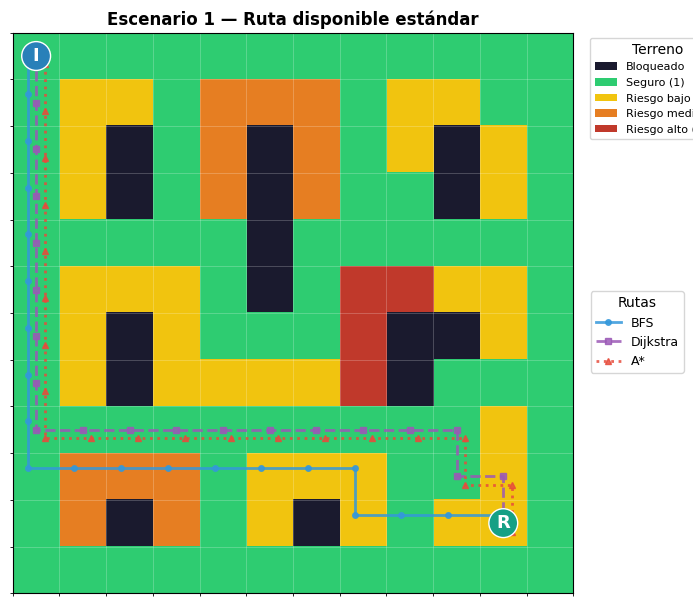

,Ruta encontrada,Pasos,Costo total de riesgo,Nodos expandidos,Tiempo (ms),Ruta válida
Algoritmo,,,,,,
BFS,True,20,44,125,0.6364,True
Dijkstra,True,20,24,128,1.0668,True
A*,True,20,24,121,1.4428,True


In [ ]:
mapa_1 = np.array([
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
    [1, 3, 3, 1, 5, 5, 5, 1, 3, 3, 1, 1],
    [1, 3, 0, 1, 5, 0, 5, 1, 3, 0, 3, 1],
    [1, 3, 0, 1, 5, 0, 5, 1, 1, 0, 3, 1],
    [1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1],
    [1, 3, 3, 3, 1, 0, 1, 10, 10, 3, 3, 1],
    [1, 3, 0, 3, 1, 1, 1, 10, 0, 0, 3, 1],
    [1, 3, 0, 3, 3, 3, 3, 10, 0, 1, 1, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 1],
    [1, 5, 5, 5, 1, 3, 3, 3, 1, 1, 3, 1],
    [1, 5, 0, 5, 1, 3, 0, 3, 1, 3, 3, 1],
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
])
INICIO_1, REFUGIO_1 = (0, 0), (10, 10)

resultados_1, tabla_1 = ejecutar_y_comparar(
    mapa_1, INICIO_1, REFUGIO_1,
    titulo="Escenario 1 — Ruta disponible estándar"
)
tabla_1


**Interpretación:** con un terreno mixto y sin cambios artificiales, los tres algoritmos
encuentran una ruta válida al refugio. BFS reporta el menor número de pasos posible (o empatado),
pero no necesariamente el menor costo de riesgo; Dijkstra y A* coinciden en el **mismo costo
total óptimo**, con A* expandiendo, en general, igual o menos nodos que Dijkstra gracias a la
guía de la heurística Manhattan.


### Escenario 2 — Bloqueo dinámico de la ruta previa

Se toma el mapa del Escenario 1 y se **bloquea una casilla clave** por donde pasaba la ruta
óptima de Dijkstra/A* en el Escenario 1, forzando un recálculo de desvío.


Bloqueando la celda clave de la ruta previa: (8, 2)


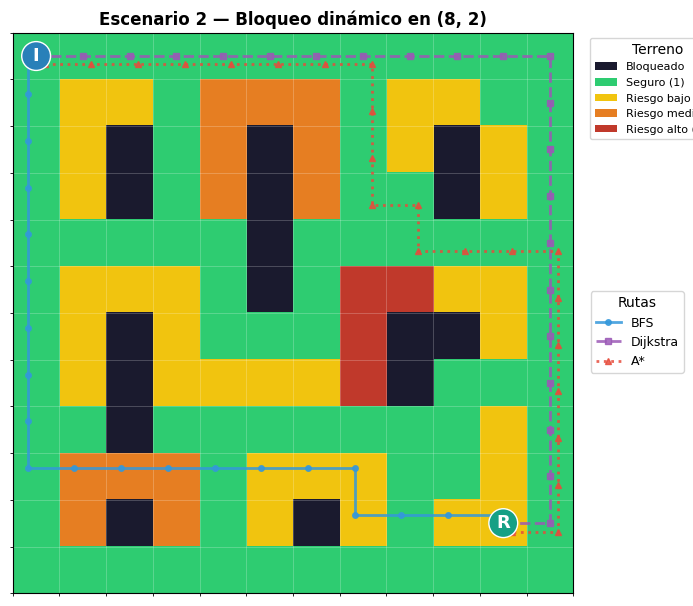

,Ruta encontrada,Pasos,Costo total de riesgo,Nodos expandidos,Tiempo (ms),Ruta válida
Algoritmo,,,,,,
BFS,True,20,44,124,0.5277,True
Dijkstra,True,22,24,127,1.9419,True
A*,True,22,24,117,1.6490,True


In [ ]:
mapa_2 = copy.deepcopy(mapa_1)

# Tomamos una celda intermedia de la ruta óptima (Dijkstra/A*) del Escenario 1 y la bloqueamos.
ruta_previa = resultados_1["Dijkstra"]["ruta"]
celda_clave = ruta_previa[len(ruta_previa) // 2]
print(f"Bloqueando la celda clave de la ruta previa: {celda_clave}")
mapa_2[celda_clave] = 0

resultados_2, tabla_2 = ejecutar_y_comparar(
    mapa_2, INICIO_1, REFUGIO_1,
    titulo=f"Escenario 2 — Bloqueo dinámico en {celda_clave}"
)
tabla_2


**Interpretación:** al bloquear una celda que formaba parte de la ruta óptima anterior, los
tres algoritmos **recalculan desde cero** (no hay memoria entre ejecuciones) y entregan un
desvío válido que evita la nueva celda bloqueada. Esto demuestra que el sistema no depende de
una ruta "cacheada": cualquier cambio en el mapa produce una nueva búsqueda consistente, y el
validador confirma que las nuevas rutas siguen cumpliendo las 4 condiciones de legitimidad.


### Escenario 3 — Refugio inaccesible

Se rodea completamente el refugio de celdas bloqueadas. Los tres algoritmos deben terminar
limpiamente, retornar `encontrada = False`, **sin ciclarse**, y el visualizador debe reportarlo
adecuadamente (sin dibujar rutas inexistentes).


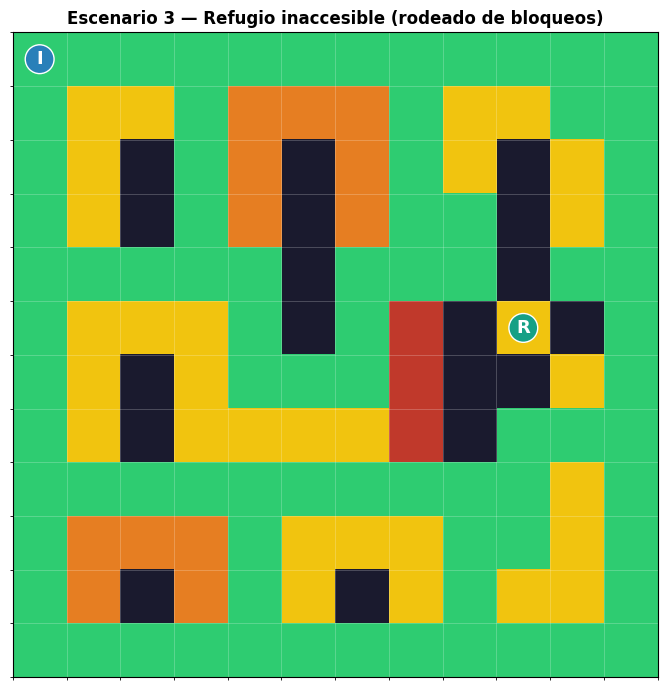

,Ruta encontrada,Pasos,Costo total de riesgo,Nodos expandidos,Tiempo (ms),Ruta válida
Algoritmo,,,,,,
BFS,False,0,0,125,0.5071,N/A (sin ruta)
Dijkstra,False,0,0,125,1.1164,N/A (sin ruta)
A*,False,0,0,125,2.8042,N/A (sin ruta)


In [ ]:
mapa_3 = copy.deepcopy(mapa_1)
REFUGIO_3 = (5, 9)

# Rodeamos completamente el refugio (las 4 celdas ortogonalmente adyacentes) con bloqueos.
for vecino in vecinos_validos(mapa_3, REFUGIO_3):
    mapa_3[vecino] = 0

resultados_3, tabla_3 = ejecutar_y_comparar(
    mapa_3, INICIO_1, REFUGIO_3,
    titulo="Escenario 3 — Refugio inaccesible (rodeado de bloqueos)"
)
tabla_3


In [ ]:
# Verificación explícita de que ningún algoritmo entra en ciclo infinito ni reporta
# una ruta falsa cuando el objetivo es inalcanzable.
for nombre, resultado in resultados_3.items():
    assert resultado["encontrada"] is False, f"{nombre} debería reportar encontrada=False"
    assert resultado["ruta"] == [], f"{nombre} no debería retornar una ruta si no hay solución"
    assert resultado["tiempo_ms"] < 2000, f"{nombre} tardó demasiado: posible ciclo"
print("✅ Los 3 algoritmos terminaron limpiamente con encontrada=False y sin ciclarse.")


✅ Los 3 algoritmos terminaron limpiamente con encontrada=False y sin ciclarse.


**Interpretación:** con el refugio completamente aislado, **no existe** ninguna secuencia de
movimientos ortogonales que lo alcance. Los tres algoritmos agotan su espacio de búsqueda
(frontera/heap vacíos) y retornan `encontrada=False` con `ruta=[]`, terminando en tiempo acotado
(no hay ciclos posibles porque los conjuntos `visitados` evitan reprocesar nodos). El
visualizador no dibuja ninguna ruta —correctamente— porque ningún resultado trae `ruta` no vacía.


### Escenario 4 — Modificación de riesgo en una región

Se toma un mapa conocido y se **incrementa el nivel de inundación** (de riesgo bajo a riesgo
severo) en el corredor principal. Se espera que Dijkstra y A* cambien de decisión hacia una ruta
alternativa, mientras BFS **sigue metiéndose al peligro** (porque BFS ignora el riesgo).


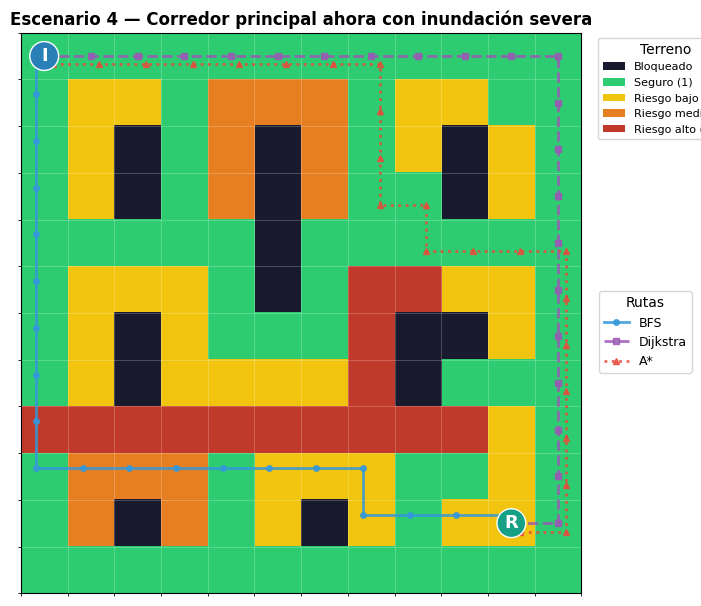

,Ruta encontrada,Pasos,Costo total de riesgo,Nodos expandidos,Tiempo (ms),Ruta válida
Algoritmo,,,,,,
BFS,True,20,53,125,0.4702,True
Dijkstra,True,22,24,104,0.8312,True
A*,True,22,24,82,0.7681,True


In [ ]:
mapa_4 = copy.deepcopy(mapa_1)

# El corredor principal (fila 8, columnas 0-9) pasa de riesgo bajo/seguro a riesgo severo (10).
mapa_4[8, 0:10] = 10

resultados_4, tabla_4 = ejecutar_y_comparar(
    mapa_4, INICIO_1, REFUGIO_1,
    titulo="Escenario 4 — Corredor principal ahora con inundación severa"
)
tabla_4


**Interpretación:** al encarecer el corredor principal, **BFS mantiene la misma lógica**: sigue
prefiriendo el camino con menos pasos, que puede seguir atravesando el corredor ahora peligroso
(su costo de riesgo sube notablemente aunque su número de pasos no cambie). En cambio, **Dijkstra
y A\* recalculan** y desvían la ruta hacia zonas de menor riesgo acumulado, incluso si eso implica
más pasos, porque ambos minimizan `g(n)` (costo), no la longitud. Esto evidencia la diferencia
fundamental de criterio entre BFS y los algoritmos conscientes de costo.


### Escenario 5 — Cuando el camino más corto NO es el más conveniente

Mapa diseñado específicamente para contrastar un **atajo recto y corto, pero severamente
inundado** (costo por celda = 10) contra un **rodeo largo mas por tierra seca** (costo por
celda = 1). Se espera:
- **BFS** elige el atajo corto y peligroso (minimiza pasos, no riesgo).
- **Dijkstra** y **A\*** eligen el rodeo seguro (minimizan costo acumulado).
- **A\*** realiza **menos trabajo** (menos nodos expandidos) que Dijkstra para llegar al mismo
  costo óptimo.


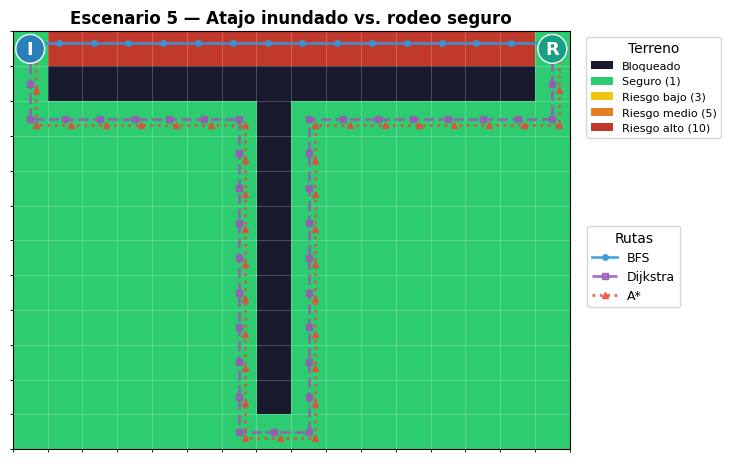

,Ruta encontrada,Pasos,Costo total de riesgo,Nodos expandidos,Tiempo (ms),Ruta válida
Algoritmo,,,,,,
BFS,True,15,141,84,1.4041,True
Dijkstra,True,37,37,158,1.4997,True
A*,True,37,37,94,7.0265,True


In [ ]:
# 12 x 16: un atajo recto en la fila superior (riesgo severo) y un único rodeo
# largo por la fila inferior (zona segura), separados por un muro horizontal.
filas, cols = 12, 16
mapa_5 = np.ones((filas, cols), dtype=int)

mapa_5[1, 1:15] = 0     # muro que obliga a elegir entre el atajo (fila 0) o bajar y rodear
mapa_5[2:11, 7] = 0     # muro vertical central: solo se cruza por la fila 0 (atajo) o fila 11 (rodeo)
mapa_5[0, 1:15] = 10    # atajo recto por inundación severa

INICIO_5, REFUGIO_5 = (0, 0), (0, 15)

resultados_5, tabla_5 = ejecutar_y_comparar(
    mapa_5, INICIO_5, REFUGIO_5,
    titulo="Escenario 5 — Atajo inundado vs. rodeo seguro"
)
tabla_5


In [ ]:
pasos_bfs = resultados_5["BFS"]["pasos"]
costo_bfs = resultados_5["BFS"]["costo_total"]
pasos_dij = resultados_5["Dijkstra"]["pasos"]
costo_dij = resultados_5["Dijkstra"]["costo_total"]
nodos_dij = resultados_5["Dijkstra"]["nodos_expandidos"]
nodos_aes = resultados_5["A*"]["nodos_expandidos"]

print(f"BFS      -> pasos={pasos_bfs:>3}  costo={costo_bfs:>4}  (camino corto, pero caro en riesgo)")
print(f"Dijkstra -> pasos={pasos_dij:>3}  costo={costo_dij:>4}  (rodeo, pero barato en riesgo)")
print(f"A*       -> pasos={resultados_5['A*']['pasos']:>3}  costo={resultados_5['A*']['costo_total']:>4}")
print(f"Nodos expandidos -> Dijkstra={nodos_dij}  |  A*={nodos_aes}  "
      f"(A* expande {'menos' if nodos_aes < nodos_dij else 'igual o más'} nodos)")

assert costo_bfs > costo_dij, "BFS debería terminar con mayor costo de riesgo que Dijkstra"
assert resultados_5["Dijkstra"]["costo_total"] == resultados_5["A*"]["costo_total"], \
    "Dijkstra y A* deben coincidir en el costo óptimo"
assert nodos_aes <= nodos_dij, "A* debería expandir igual o menos nodos que Dijkstra"
print("Comportamiento esperado confirmado numéricamente. ✅")


BFS      -> pasos= 15  costo= 141  (camino corto, pero caro en riesgo)
Dijkstra -> pasos= 37  costo=  37  (rodeo, pero barato en riesgo)
A*       -> pasos= 37  costo=  37
Nodos expandidos -> Dijkstra=158  |  A*=94  (A* expande menos nodos)
Comportamiento esperado confirmado numéricamente. ✅


**Interpretación:** el resultado confirma la tesis central del proyecto. **BFS** encuentra el
camino con menos pasos —el atajo por la fila superior— sin notar que ese atajo tiene un costo de
riesgo mucho más alto. **Dijkstra** y **A\*** descartan ese atajo porque, aunque más corto en
pasos, su costo acumulado `g(n)` es mayor; ambos convergen en el **mismo rodeo óptimo** con el
**mismo costo total**. La diferencia entre Dijkstra y A\* está en la **eficiencia**: A\* expande
menos nodos porque su heurística Manhattan dirige la búsqueda hacia el refugio en vez de explorar
uniformemente en todas direcciones como hace Dijkstra.


### Escenario 6 — Prueba adicional "Caza-errores" (robustez e integridad)

Suite de pruebas de borde que verifica que el sistema **detecta y captura errores de entrada
antes de ejecutar los algoritmos**, evitando resultados falsos:

(a) inicio o refugio sobre una celda bloqueada/inundada,
(b) inicio == refugio (caso trivial, 0 pasos),
(c) mapa con un valor de riesgo negativo inválido.


In [ ]:
print("=" * 70)
print("CASO (a): inicio sobre una celda bloqueada")
print("=" * 70)
mapa_a = copy.deepcopy(mapa_1)
inicio_a, refugio_a = (2, 2), (10, 10)   # mapa_1[2, 2] == 0 (bloqueada)
assert mapa_a[inicio_a] == 0
es_valido, errores = validar_entrada(mapa_a, inicio_a, refugio_a)
print("Entrada válida:", es_valido)
for e in errores:
    print("  -", e)
assert es_valido is False and len(errores) > 0
resultados_a, tabla_a = ejecutar_y_comparar(mapa_a, inicio_a, refugio_a,
                                             titulo="Caso (a): inicio bloqueado")
assert resultados_a == {}, "No deberían ejecutarse algoritmos con entrada inválida"
print("✅ El sistema detectó y capturó el error ANTES de ejecutar los algoritmos.")


CASO (a): inicio sobre una celda bloqueada
Entrada válida: False
  - El punto de inicio (2, 2) cae sobre una celda bloqueada/inundada.
⚠️  Entrada inválida, no se ejecutan los algoritmos:
   - El punto de inicio (2, 2) cae sobre una celda bloqueada/inundada.
✅ El sistema detectó y capturó el error ANTES de ejecutar los algoritmos.


In [ ]:
print("=" * 70)
print("CASO (b): Inicio == Refugio")
print("=" * 70)
mismo_punto = (0, 0)
for nombre, fn in ALGORITMOS.items():
    resultado = fn(mapa_1, mismo_punto, mismo_punto)
    es_valida, errores_validacion = validar_ruta(mapa_1, mismo_punto, mismo_punto, resultado)
    print(f"{nombre:9s} -> encontrada={resultado['encontrada']}  pasos={resultado['pasos']}  "
          f"costo={resultado['costo_total']}  ruta={resultado['ruta']}  válida={es_valida}")
    assert resultado["pasos"] == 0
    assert resultado["ruta"] == [mismo_punto]
    assert es_valida
print("✅ Los 3 algoritmos manejan correctamente el caso trivial inicio == refugio (0 pasos).")


CASO (b): Inicio == Refugio
BFS       -> encontrada=True  pasos=0  costo=0  ruta=[(0, 0)]  válida=True
Dijkstra  -> encontrada=True  pasos=0  costo=0  ruta=[(0, 0)]  válida=True
A*        -> encontrada=True  pasos=0  costo=0  ruta=[(0, 0)]  válida=True
✅ Los 3 algoritmos manejan correctamente el caso trivial inicio == refugio (0 pasos).


In [ ]:
print("=" * 70)
print("CASO (c): mapa con valor de riesgo negativo inválido")
print("=" * 70)
mapa_c = copy.deepcopy(mapa_1)
mapa_c[4, 4] = -7   # valor de riesgo negativo NO permitido (distinto del código de bloqueo -1)

es_valido, errores = validar_entrada(mapa_c, INICIO_1, REFUGIO_1)
print("Entrada válida:", es_valido)
for e in errores:
    print("  -", e)
assert es_valido is False
assert any("negativo" in e for e in errores)

resultados_c, tabla_c = ejecutar_y_comparar(mapa_c, INICIO_1, REFUGIO_1,
                                             titulo="Caso (c): riesgo negativo inválido")
assert resultados_c == {}, "No deberían ejecutarse algoritmos con un riesgo negativo inválido"
print("✅ El sistema detectó el valor de riesgo negativo y evitó ejecutar resultados falsos.")


CASO (c): mapa con valor de riesgo negativo inválido
Entrada válida: False
  - El mapa contiene valores de riesgo negativos no permitidos (ej. -7). Esto rompería la optimalidad de Dijkstra/A*, que asumen costos no negativos.
⚠️  Entrada inválida, no se ejecutan los algoritmos:
   - El mapa contiene valores de riesgo negativos no permitidos (ej. -7). Esto rompería la optimalidad de Dijkstra/A*, que asumen costos no negativos.
✅ El sistema detectó el valor de riesgo negativo y evitó ejecutar resultados falsos.


**Interpretación:** la suite caza-errores confirma que `validar_entrada` actúa como una
**barrera previa a la ejecución**: ningún algoritmo corre sobre datos corruptos o inconsistentes.
El caso (a) demuestra que el sistema no asume silenciosamente que el punto de partida es
transitable. El caso (b) confirma que el caso trivial (0 pasos) se maneja sin errores
aritméticos ni de reconstrucción de ruta. El caso (c) es el más delicado: un **costo negativo**
rompería la propiedad de optimalidad de Dijkstra/A* (que dependen de que `g(n)` sea
monótonamente no decreciente a lo largo de la búsqueda); por eso el sistema lo detecta y
**rechaza la ejecución en vez de arriesgarse a entregar una ruta "óptima" que en realidad no lo
es**.


## 5. Declaración de uso de herramientas de IA y verificación

**Herramientas de IA utilizadas:** este notebook fue desarrollado con apoyo de un asistente de
IA (Claude, de Anthropic) como herramienta de asistencia en programación, para: (i) estructurar
el código de forma modular, (ii) redactar y organizar la documentación en Markdown, y (iii)
proponer los mapas de prueba de cada escenario. El diseño de la rúbrica, los criterios de
evaluación y la revisión final del contenido fueron definidos y validados por la persona autora
del proyecto.

**Cómo se verificó el código (no se confió ciegamente en la salida generada):**

1. **Validación automatizada por ruta (`validar_ruta`):** cada resultado de cada algoritmo, en
   cada uno de los 6 escenarios, fue pasado por `validar_ruta`, que comprueba
   independientemente las 4 condiciones de legitimidad (extremos correctos, adyacencia
   ortogonal, ausencia de celdas bloqueadas, y coincidencia exacta entre el costo reportado y el
   costo real recalculado desde cero a partir del mapa).
2. **Validación de integridad de entrada (`validar_entrada`):** antes de cada ejecución se
   verifica que inicio/refugio estén dentro del mapa, no caigan sobre celdas bloqueadas, y que
   el mapa no contenga valores de riesgo negativos inválidos — evitando así resultados
   "óptimos" falsos.
3. **Pruebas de casos borde (Escenario 6):** se diseñaron deliberadamente entradas inválidas o
   triviales (inicio bloqueado, inicio == refugio, riesgo negativo) con `assert` explícitos sobre
   el comportamiento esperado, de forma que el notebook **falla ruidosamente** (en vez de
   continuar en silencio) si alguna de estas garantías se rompe.
4. **Comprobación manual de costos en cuadrículas controladas:** en el Escenario 5 se diseñó a
   mano un mapa donde el costo del atajo (`5 celdas × 10 = 50`, aprox.) y del rodeo
   (`N celdas × 1`) se pueden calcular manualmente y contrastar contra `costo_total`, confirmando
   que la suma de riesgos coincide con el cálculo esperado y que la relación de orden
   (`costo_atajo > costo_rodeo`) se cumple tal como predice la teoría.
5. **Consistencia cruzada entre algoritmos:** en todos los escenarios con solución, se verificó
   que `Dijkstra.costo_total == A*.costo_total` (ambos óptimos en costo) y que
   `A*.nodos_expandidos <= Dijkstra.nodos_expandidos` (A* al menos igual de eficiente gracias a
   la heurística admisible).
